**Dự án Supervised learning: Dự đoán nhiệt độ (Temperature) từ dữ liệu thời tiết**

**Mục tiêu:** dùng các cột còn lại (độ ẩm, áp suất, mùa, loại thời tiết,...) để dự đoán cột **Temperature** (biến số liên tục) → bài toán **Regression**.

**Các bước trong bài toán này:**

Bước 0: Import thư viện, đọc dữ liệu, chia train/test

Bước 1: EDA để tìm insight trong dữ liệu

Bước 2: Làm sạch và chuẩn hóa dữ liệu

Bước 3: Feature engineering: tạo đặc trưng dưa trên hiểu biết về thời tiết

Bước 4: Xây dựng mô hình (pipeline, so sánh mô hình, tinh chỉnh, diễn giải

Bước 5: Đánh giá (MSE, RMSE, MAE, R^2)

Bước 6: Nhìn lại (bước nào làm mô hình yếu đi, bước nào làm mô hình tốt lên)


**Bước 0: Chuẩn bị**

In [2]:
# Import các thư viện cần dùng
import warnings                       # thư viện quản lý cảnh báo
warnings.filterwarnings('ignore')     # tắt cảnh báo không quan trọng cho output gọn hơn
import os                             # thao tác với file/thư mục
import numpy as np                    # tính toán số học trên mảng
import pandas as pd                   # xử lý dữ liệu dạng bảng (DataFrame)
import matplotlib.pyplot as plt       # vẽ biểu đồ cơ bản
import seaborn as sns                 # vẽ biểu đồ đẹp hơn, xây trên matplotlib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer          # áp dụng xử lý khác nhau cho từng nhóm cột
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # chuẩn hóa Z-score / mã hóa one-hot
from sklearn.pipeline import Pipeline                  # nối các bước xử lý + mô hình thành 1 chuỗi
from sklearn.dummy import DummyRegressor               # mô hình "ngốc" luôn đoán giá trị trung bình
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score)

sns.set_theme(style='whitegrid')      # nền lưới trắng cho biểu đồ
pd.set_option('display.width', 200)   # cho phép bảng in rộng hơn đến 200 kí tự
pd.set_option('display.max_columns', 30)  # hiện tối đa 30 cột khi in bảng
RANDOM_STATE = 42                     # số cố định để kết quả chạy lại luôn giống nhau

In [3]:
# Đọc dữ liệu
FILE_NAME = 'weather_classification_data.csv'   # tên file dữ liệu
if not os.path.exists(FILE_NAME):               # nếu file chưa có trong Colab
    from google.colab import files              # công cụ upload của Colab
    files.upload()                              # hiện nút chọn file để tải lên

df = pd.read_csv(FILE_NAME)                     # đọc file CSV thành bảng DataFrame
print('Kích thước (số dòng, số cột):', df.shape)
display(df.head())                              # xem 5 dòng đầu
df.info()                                       # xem tên cột, số dòng không null, kiểu dữ liệu

Saving weather_classification_data.csv to weather_classification_data.csv
Kích thước (số dòng, số cột): (13200, 11)


,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,14.0,73,9.5,82.0,partly cloudy,1010.82,2,Winter,3.5,inland,Rainy
1,39.0,96,8.5,71.0,partly cloudy,1011.43,7,Spring,10.0,inland,Cloudy
2,30.0,64,7.0,16.0,clear,1018.72,5,Spring,5.5,mountain,Sunny
3,38.0,83,1.5,82.0,clear,1026.25,7,Spring,1.0,coastal,Sunny
4,27.0,74,17.0,66.0,overcast,990.67,1,Winter,2.5,mountain,Rainy


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13200 entries, 0 to 13199
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Temperature           13200 non-null  float64
 1   Humidity              13200 non-null  int64  
 2   Wind Speed            13200 non-null  float64
 3   Precipitation (%)     13200 non-null  float64
 4   Cloud Cover           13200 non-null  object 
 5   Atmospheric Pressure  13200 non-null  float64
 6   UV Index              13200 non-null  int64  
 7   Season                13200 non-null  object 
 8   Visibility (km)       13200 non-null  float64
 9   Location              13200 non-null  object 
 10  Weather Type          13200 non-null  object 
dtypes: float64(5), int64(2), object(4)
memory usage: 1.1+ MB


**Chia train/test ngay từ đầu.** Mọi thứ "học từ dữ liệu" (ngưỡng IQR, mô hình, tham số chuẩn hóa) chỉ được học từ tập **train**. Tập **test** giữ lại để chấm điểm cuối cùng, như bài thi mà mô hình chưa từng thấy. Nếu làm ngược lại, thông tin của test bị "rò rỉ" sang train (*data leakage*) và điểm số sẽ đẹp hơn thực tế.

In [4]:
TARGET = 'Temperature'                 # cột cần dự đoán (nhãn)

# Chia 80% dòng làm train, 20% làm test (chọn ngẫu nhiên nhưng cố định bằng random_state)
train_raw, test_raw = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)

print('Train:', train_raw.shape, '| Test:', test_raw.shape)

# Danh sách cột số và cột phân loại (không gồm Temperature vì đó là nhãn)
num_base = ['Humidity', 'Wind Speed', 'Precipitation (%)', 'Atmospheric Pressure', 'UV Index', 'Visibility (km)']
cat_base = ['Cloud Cover', 'Season', 'Location', 'Weather Type']

Train: (10560, 11) | Test: (2640, 11)


**Bước 1. EDA (Exploratory Data Analysis): tìm insight**

**Tổng quan dữ liệu:** File có 13.200 dòng và 11 cột (7 cột số, 4 cột phân loại).

**Insight:** Dữ liệu có giá trị sai về mặt vật lý

- Cột Temperature có nhiều giá trị quá lớn hoặc quá nhỏ so với thực tế ghi nhận được
- Cột Humidity (%) và Precipitation (%) có các số lớn hơn cả 100 (toàn các giá trị 101-109)
- Cột Atmospheric Pressure có nhiều dòng quá thấp hoặc quá cao so với kỉ lục khí quyển (870 đến 1085 hPa)



**Bước 2. Làm sạch và chuẩn hóa dữ liệu**

**2.1** Tính tổng dữ liệu thiếu (missing) và dữ liệu trùng (duplicated) ở mỗi cột

In [6]:
print('Số ô bị thiếu (null) ở mỗi cột:')
print(df.isna().sum())                           # isna() đánh dấu ô thiếu, sum() đếm theo cột
print()
print('Số dòng bị trùng lặp hoàn toàn:', df.duplicated().sum())  # duplicated() đánh dấu dòng trùng dòng trước đó

Số ô bị thiếu (null) ở mỗi cột:
Temperature             0
Humidity                0
Wind Speed              0
Precipitation (%)       0
Cloud Cover             0
Atmospheric Pressure    0
UV Index                0
Season                  0
Visibility (km)         0
Location                0
Weather Type            0
dtype: int64

Số dòng bị trùng lặp hoàn toàn: 0




**2.2** Loại Outlier bằng 3 cách: Rule-based, IQR, Z-score

- **Rule-based:** dùng *kiến thức nghiệp vụ* để đặt ngưỡng hợp lý theo insight
- **IQR:** coi là outlier nếu nằm ngoài `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`.
- **Z-score:** coi là outlier nếu cách trung bình hơn 3 độ lệch chuẩn (`|z| > 3`).

Ta đếm số outlier theo từng cách để so sánh.

In [5]:
# Ngưỡng hợp lý theo kiến thức thực tế về khí tượng (rule-based)
physical_rules = {
    'Temperature':          (-89, 57),    # kỷ lục lạnh nhất ~ -89°C, nóng nhất ~ 57°C trên Trái Đất
    'Humidity':             (0, 100),     # độ ẩm là phần trăm
    'Precipitation (%)':    (0, 100),     # lượng mưa dạng phần trăm
    'Atmospheric Pressure': (870, 1085),  # khoảng áp suất kỷ lục đã ghi nhận (hPa)
    'UV Index':             (0, 16),      # chỉ số UV thực tế hiếm khi vượt 16
    'Wind Speed':           (0, 120),     # gió trên 120 km/h là bão cực mạnh
    'Visibility (km)':      (0, 100),     # tầm nhìn xa tối đa hợp lý
}

def iqr_bounds(series):
    q1 = series.quantile(0.25)            # phân vị 25%
    q3 = series.quantile(0.75)            # phân vị 75%
    iqr = q3 - q1                         # khoảng tứ phân vị
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr # cận dưới và cận trên

rows = []                                 # danh sách để gom kết quả từng cột
for col in [TARGET] + num_base:           # duyệt qua từng cột số (gồm cả Temperature)
    lo, hi = physical_rules[col]                                  # ngưỡng rule-based
    n_rule = ((df[col] < lo) | (df[col] > hi)).sum()              # số dòng vi phạm rule
    i_lo, i_hi = iqr_bounds(df[col])                              # cận IQR
    n_iqr = ((df[col] < i_lo) | (df[col] > i_hi)).sum()           # số dòng ngoài cận IQR
    z = (df[col] - df[col].mean()) / df[col].std()                # Z-score của từng dòng
    n_z = (z.abs() > 3).sum()                                     # số dòng có |z| > 3
    rows.append({'Cột': col, 'Rule-based': n_rule, 'IQR': n_iqr, 'Z-score': n_z,
                 'Cận IQR': f'[{i_lo:.1f}, {i_hi:.1f}]'})
display(pd.DataFrame(rows))

,Cột,Rule-based,IQR,Z-score,Cận IQR
0,Temperature,250,92,92,"[-36.5, 71.5]"
1,Humidity,416,0,0,"[16.5, 124.5]"
2,Wind Speed,0,404,236,"[-7.8, 26.2]"
3,Precipitation (%),392,0,0,"[-75.5, 176.5]"
4,Atmospheric Pressure,564,927,556,"[961.8, 1049.7]"
5,UV Index,0,0,0,"[-8.0, 16.0]"
6,Visibility (km),0,383,282,"[-3.8, 14.2]"


**Nhận xét quan trọng khi so sánh 3 cách**

- `Humidity` và `Precipitation (%)` có các giá trị 101 đến 109 (phi lý vì là phần trăm). **IQR và Z-score không phát hiện ra** vì cận IQR của hai cột này rất rộng (xem cột "Cận IQR"), chỉ **rule-based** bắt được. Kết luận: IQR/Z-score là công cụ thống kê, chỉ bắt "giá trị lệch so với phần đông", còn "giá trị sai về mặt ý nghĩa" cần kiến thức nghiệp vụ.
- Ngược lại, `Wind Speed` và `Visibility (km)` bị IQR đánh dấu nhiều, nhưng gió 40 km/h hay tầm nhìn 20 km là hoàn toàn có thật. Đó là dữ liệu lệch phải tự nhiên chứ không phải lỗi. Vì vậy **không xóa** chúng theo IQR.

**Quyết định xử lý (rule-based)**
| Cột | Cách xử lý | Lý do |
|---|---|---|
| Temperature (nhãn) ngoài [-89, 57] | **Xóa dòng** | Nhãn sai thì không thể "đoán" lại giá trị đúng, không được sửa bừa |
| Atmospheric Pressure ngoài [870, 1085] | **Xóa dòng** | Giá trị phi thực tế, không biết giá trị gốc là gì |
| Humidity, Precipitation > 100 | **Kẹp (clip) về 100** | Chỉ vượt 100 một chút, giữ lại dòng và đưa về mức tối đa hợp lệ |

In [7]:
def apply_rules(d, temp_rule=True, pressure_rule=True, clip_pct=True):
    """Làm sạch theo rule-based. Các tham số True/False cho phép tắt từng quy tắc"""

    d = d.copy()                                          # copy để không sửa vào bảng gốc
    if clip_pct:                                          # quy tắc 1: kẹp phần trăm về tối đa 100
        d['Humidity'] = d['Humidity'].clip(upper=100)
        d['Precipitation (%)'] = d['Precipitation (%)'].clip(upper=100)
    keep = pd.Series(True, index=d.index)                 # ban đầu giữ tất cả dòng
    if temp_rule:                                         # quy tắc 2: Temperature hợp lý
        t_lo, t_hi = physical_rules['Temperature']
        keep &= d['Temperature'].between(t_lo, t_hi)      # between(a, b) = a <= x <= b
    if pressure_rule:                                     # quy tắc 3: Pressure hợp lý
        p_lo, p_hi = physical_rules['Atmospheric Pressure']
        keep &= d['Atmospheric Pressure'].between(p_lo, p_hi)
    return d[keep]                                        # chỉ giữ các dòng hợp lệ

# Áp dụng cho cả train và test (rule-based dựa trên kiến thức vật lý, không "học" từ dữ liệu nên an toàn)
train_clean = apply_rules(train_raw)
test_clean = apply_rules(test_raw)
print(f'Train: {len(train_raw)} -> {len(train_clean)} dòng (bỏ {len(train_raw) - len(train_clean)})')
print(f'Test : {len(test_raw)} -> {len(test_clean)} dòng (bỏ {len(test_raw) - len(test_clean)})')

Train: 10560 -> 9912 dòng (bỏ 648)
Test : 2640 -> 2474 dòng (bỏ 166)


**2.3** Kiểm tra lại bằng Z-score sau khi làm sạch, và chuẩn hóa dữ liệu

Sau khi bỏ các giá trị phi lý, ta kiểm tra xem Temperature còn dòng nào lệch quá xa không.

In [8]:
z_temp = (train_clean[TARGET] - train_clean[TARGET].mean()) / train_clean[TARGET].std()  # Z-score của Temperature
print('Số dòng |z| > 3 còn lại trong train:', (z_temp.abs() > 3).sum())
print('Temperature nhỏ nhất / lớn nhất trong train sau làm sạch:',
      train_clean[TARGET].min(), '/', train_clean[TARGET].max())

Số dòng |z| > 3 còn lại trong train: 0
Temperature nhỏ nhất / lớn nhất trong train sau làm sạch: -25.0 / 57.0


**Chuẩn hóa (scaling).** Z-score còn là tên của một phép chuẩn hóa: `z = (x − trung bình) / độ lệch chuẩn`, đưa mọi cột số về cùng thang đo (trung bình 0, độ lệch chuẩn 1). Việc này giúp các mô hình tuyến tính (Linear/Ridge) so sánh hệ số công bằng giữa cột có đơn vị khác nhau (áp suất ~1000 so với UV ~4).

**Bước 3. Feature engineering**

Ta thêm các yếu tố có thể ảnh hưởng đến nhiệt độ từ kiến thức về thời tiết :

| Đặc trưng mới | Ý tưởng thời tiết |
|---|---|
| `Is_Winter` | Mùa đông lạnh hơn hẳn ba mùa còn lại | Đông 9,3 °C so với 25,1 °C |
| `Is_Coastal` | Vùng ven biển có biển điều hòa nên ấm hơn inland và mountain |
| `Cloud_Lever` | Trời càng nhiều mây thì càng ít nắng chiếu xuống nên càng mát |

Mã hóa Cloud Cover theo thứ tự: clear=0, partly cloudy=1, cloudy=2, overcast=3

In [10]:
def add_features(d):
    """Tạo thêm các đặc trưng mới từ kiến thức thời tiết"""
    d = d.copy()

    # 1) Cloud_Level: đổi chữ thành số theo thứ tự từ ít mây đến nhiều mây
    cloud_map = {'clear': 0, 'partly cloudy': 1, 'cloudy': 2, 'overcast': 3}
    d['Cloud_Level'] = d['Cloud Cover'].map(cloud_map)

    # 2) Is_Winter: 1 nếu là mùa đông, ngược lại 0
    d['Is_Winter'] = (d['Season'] == 'Winter').astype(int)

    # 3) Is_Coastal: 1 nếu ở ven biển, ngược lại 0
    d['Is_Coastal'] = (d['Location'] == 'coastal').astype(int)

    return d

# Áp dụng cho tập train và test đã được làm sạch
train_fe = add_features(train_clean)
test_fe = add_features(test_clean)

# Khai báo danh sách đặc trưng mới đầy đủ
num_fe = num_base + ['Cloud_Level', 'Is_Winter', 'Is_Coastal']
cat_fe = cat_base

# Kiểm tra nhanh trên tập train_fe
print("Nhiệt độ trung bình theo mức độ mây (Cloud_Level):")
print(train_fe.groupby('Cloud_Level')['Temperature'].mean())
print("\nNhiệt độ trung bình theo mùa đông (Is_Winter):")
print(train_fe.groupby('Is_Winter')['Temperature'].mean())
print("\nNhiệt độ trung bình theo vùng ven biển (Is_Coastal):")
print(train_fe.groupby('Is_Coastal')['Temperature'].mean())

Nhiệt độ trung bình theo mức độ mây (Cloud_Level):
Cloud_Level
0    32.195971
1    20.909564
2    14.434286
3    12.200302
Name: Temperature, dtype: float64

Nhiệt độ trung bình theo mùa đông (Is_Winter):
Is_Winter
0    25.339761
1     9.809325
Name: Temperature, dtype: float64

Nhiệt độ trung bình theo vùng ven biển (Is_Coastal):
Is_Coastal
0    16.201130
1    25.091422
Name: Temperature, dtype: float64


**Bước 4. Xây dựng mô hình**

**4.1** Thiết kế pipeline

**Pipeline** là một chuỗi bước xử lý nối liền nhau, gồm: chuẩn hóa cột số, mã hóa cột phân loại, rồi mới đến mô hình. Ưu điểm lớn nhất là mọi tham số "học từ dữ liệu" (trung bình, độ lệch chuẩn, danh sách nhóm) chỉ được học trên dữ liệu train, nên không bị rò rỉ khi dự đoán trên test.

- Cột số → `StandardScaler` (Z-score).
- Cột phân loại → `OneHotEncoder` (mỗi nhóm thành một cột 0/1).

In [12]:
def make_pipeline(model, num_features, cat_features, scale=True):
    num_step = StandardScaler() if scale else 'passthrough'   # chuẩn hóa Z-score hoặc giữ nguyên
    prep = ColumnTransformer([
        ('num', num_step, num_features),                                              # xử lý cột số
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features),  # one-hot cột phân loại
    ])
    return Pipeline([('prep', prep), ('model', model)])       # nối bước tiền xử lý với mô hình

def evaluate(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)                  # MSE: trung bình bình phương sai số
    return {'MSE': mse,
            'RMSE': np.sqrt(mse),                             # RMSE: căn của MSE, cùng đơn vị với Temperature (°C)
            'MAE': mean_absolute_error(y_true, y_pred),       # MAE: trung bình sai số tuyệt đối
            'R2': r2_score(y_true, y_pred)}                   # R2: tỉ lệ biến thiên của nhãn mà mô hình giải thích được

def fit_and_score(pipe, train_df, test_df, num_features, cat_features):
    pipe.fit(train_df[num_features + cat_features], train_df[TARGET])      # học trên train
    pred = pipe.predict(test_df[num_features + cat_features])              # dự đoán test
    return evaluate(test_df[TARGET], pred)                                 # chấm điểm với đáp án thật

**4.2** So sánh 2 mô hình (chỉ dùng tập train)

Hai mô hình so sánh: *Dummy* (luôn đoán trung bình, làm mốc: mô hình nào không thắng Dummy thì vô dụng), *Linear Regression* (mô hình chính của bài toán)

In [14]:
# Hai mô hình cần so sánh, mỗi mô hình nằm trong một pipeline
candidates = {
    'Dummy (đoán trung bình)': make_pipeline(DummyRegressor(), num_base, cat_base),
    'Linear Regression':       make_pipeline(LinearRegression(), num_base, cat_base),
}

X_train = train_clean[num_base + cat_base]   # các cột đầu vào của tập train
y_train = train_clean[TARGET]                # cột Temperature (nhãn) của tập train

# Tách 20% của tập train làm tập validation (80% còn lại để huấn luyện)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=RANDOM_STATE)
print('Huấn luyện:', len(X_tr), 'dòng | Validation:', len(X_val), 'dòng')

rows = []                                    # danh sách để gom kết quả từng mô hình
for name, pipe in candidates.items():        # chạy lần lượt từng mô hình
    pipe.fit(X_tr, y_tr)                     # học trên phần huấn luyện
    pred = pipe.predict(X_val)               # dự đoán trên tập validation (mô hình chưa từng thấy)
    rmse = np.sqrt(mean_squared_error(y_val, pred))   # RMSE giữa đáp án thật và dự đoán
    rows.append({'Mô hình': name, 'RMSE trên tập validation': rmse})

display(pd.DataFrame(rows).round(3))         # in bảng kết quả

Huấn luyện: 7929 dòng | Validation: 1983 dòng


,Mô hình,RMSE trên tập validation
0,Dummy (đoán trung bình),15.381
1,Linear Regression,9.127


**4.3** Mô hình cuối: Linear Regression

Linear Regression vượt xa mô hình mốc Dummy ở bước trên và có ưu điểm lớn là dễ diễn giải: mỗi cột có một hệ số cho biết mức ảnh hưởng đến nhiệt độ (xem 4.4).

- Cột số được chuẩn hóa Z-score (`StandardScaler`) nên hệ số của các cột so sánh được với nhau.
- Cột phân loại được mã hóa one-hot.
- Sau khi đã chọn mô hình, ta huấn luyện lại trên toàn bộ tập train (không chỉ 80% dùng khi so sánh), vì có thêm dữ liệu thì mô hình học tốt hơn.

Mô hình cuối dùng đặc trưng gốc (6 cột số và 4 cột phân loại).

In [15]:
num_final = num_base                 # danh sách cột số dùng cho mô hình cuối
cat_final = cat_base                 # danh sách cột phân loại dùng cho mô hình cuối

# Pipeline: chuẩn hóa cột số + one-hot cột phân loại + Linear Regression (scale=True là mặc định)
final_model = make_pipeline(LinearRegression(), num_final, cat_final)

final_model.fit(train_clean[num_final + cat_final], train_clean[TARGET])   # học trên toàn bộ tập train
print('Đã huấn luyện xong mô hình cuối (Linear Regression).')

Đã huấn luyện xong mô hình cuối (Linear Regression).


**4.4** Diễn giải mô hình: cột nào ảnh hưởng nhiều?

Ta dùng hệ số của Linear Regression để dễ đọc. Vì cột số đã được chuẩn hóa nên hệ số cho biết: cột số tăng 1 độ lệch chuẩn (hoặc dòng thuộc nhóm đó) thì nhiệt độ dự đoán thay đổi bao nhiêu °C, các yếu tố khác giữ nguyên. Hệ số lớn (dương hay âm) nghĩa là cột đó ảnh hưởng mạnh.

In [16]:
lin = make_pipeline(LinearRegression(), num_base, cat_base)        # pipeline với Linear Regression
lin.fit(train_clean[num_base + cat_base], train_clean[TARGET])     # học trên train
coef = pd.Series(lin.named_steps['model'].coef_,                   # lấy hệ số của mô hình
                 index=lin.named_steps['prep'].get_feature_names_out()).sort_values()  # gắn tên cột và sắp xếp
print('Hệ số Linear Regression (đơn vị: °C):')
print(coef.round(2))

Hệ số Linear Regression (đơn vị: °C):
cat__Weather Type_Snowy          -18.94
cat__Cloud Cover_cloudy           -2.54
cat__Season_Winter                -0.63
cat__Cloud Cover_overcast         -0.26
cat__Location_mountain            -0.13
cat__Location_inland              -0.10
cat__Season_Spring                 0.02
num__Visibility (km)               0.03
num__Humidity                      0.08
cat__Season_Autumn                 0.10
num__Wind Speed                    0.13
num__Precipitation (%)             0.20
cat__Location_coastal              0.23
cat__Cloud Cover_partly cloudy     0.48
cat__Season_Summer                 0.50
num__Atmospheric Pressure          0.60
num__UV Index                      0.94
cat__Cloud Cover_clear             2.33
cat__Weather Type_Cloudy           4.15
cat__Weather Type_Rainy            4.51
cat__Weather Type_Sunny           10.29
dtype: float64


**Bước 5. Đánh giá trên tập test**

Ta dùng tập test (chưa từng thấy) để chấm điểm mô hình cuối cùng.

- **MSE** = trung bình của (sai số)². Phạt nặng các sai số lớn. Đơn vị là °C².
- **RMSE** = √MSE. Cùng đơn vị °C, hiểu là "sai số điển hình của mô hình".
- **MAE** = trung bình |sai số|. Dễ hiểu, ít bị ảnh hưởng bởi vài điểm sai lớn.
- **R²**: 1 là hoàn hảo, 0 là bằng mô hình luôn đoán trung bình.

In [18]:
# 5.1 Bảng điểm trên tập test
X_test = test_fe[num_final + cat_final]          # các cột đầu vào của tập test
y_test = test_fe[TARGET]                         # đáp án thật (Temperature) của tập test

# Mô hình mốc: luôn đoán giá trị trung bình (học trên train, chấm trên test)
dummy_res = fit_and_score(make_pipeline(DummyRegressor(), num_base, cat_base),
                          train_fe, test_fe, num_base, cat_base)

# Mô hình cuối (Linear Regression) đã được huấn luyện ở 4.3, giờ chỉ cần dự đoán
y_pred = final_model.predict(X_test)             # dự đoán nhiệt độ cho tập test
final_res = evaluate(y_test, y_pred)             # tính MSE, RMSE, MAE, R2

score_table = pd.DataFrame({'Dummy (mốc)': dummy_res,
                            'Mô hình cuối (Linear Regression)': final_res}).T.round(3)
display(score_table)                             # in bảng so sánh

# Khoảng dao động 95% của RMSE (bootstrap: lấy mẫu lại ngẫu nhiên các dòng test 1000 lần)
rng = np.random.default_rng(RANDOM_STATE)        # bộ sinh số ngẫu nhiên có cố định hạt giống
sq_err = ((y_test - y_pred) ** 2).values         # bình phương sai số của từng dòng test
boot = [np.sqrt(sq_err[rng.integers(0, len(sq_err), len(sq_err))].mean()) for _ in range(1000)]
print('RMSE mô hình cuối: %.2f, khoảng 95%%: [%.2f, %.2f]' % (final_res['RMSE'], *np.percentile(boot, [2.5, 97.5])))
print('RMSE giảm so với Dummy: %.1f%%' % (100 * (1 - final_res['RMSE'] / dummy_res['RMSE'])))

,MSE,RMSE,MAE,R2
Dummy (mốc),246.193,15.691,13.036,-0.006
Mô hình cuối (Linear Regression),80.493,8.972,6.696,0.671


RMSE mô hình cuối: 8.97, khoảng 95%: [8.53, 9.40]
RMSE giảm so với Dummy: 42.8%


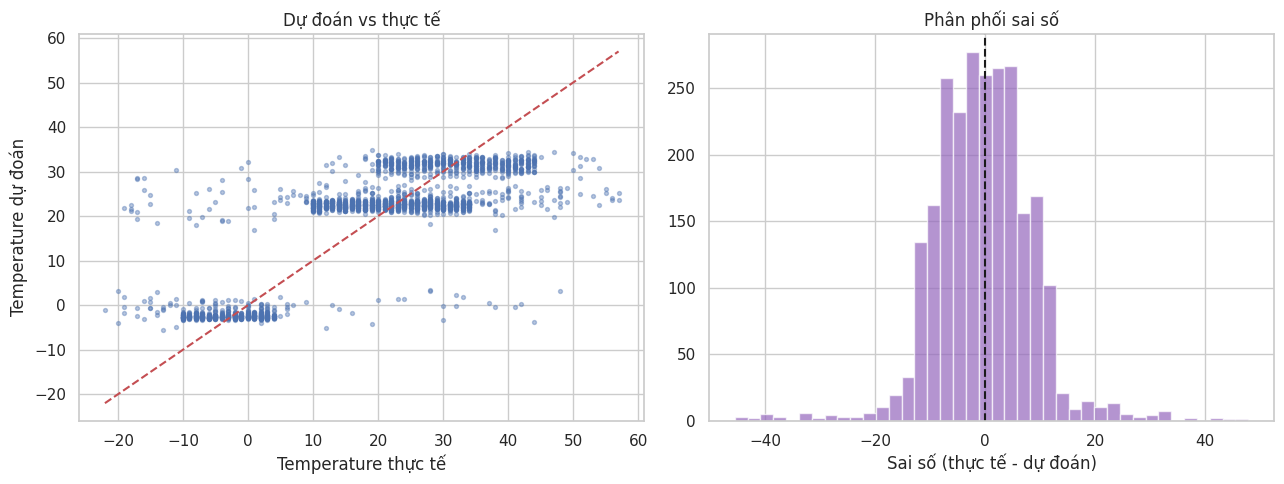

--- MAE theo Weather Type ---
{'Cloudy': 7.26, 'Rainy': 7.61, 'Snowy': 4.84, 'Sunny': 7.34}
--- MAE theo Season ---
{'Autumn': 7.87, 'Spring': 7.83, 'Summer': 7.4, 'Winter': 5.44}
--- MAE theo Location ---
{'coastal': 7.53, 'inland': 6.5, 'mountain': 6.34}


In [19]:
# 5.2 Biểu đồ: dự đoán vs thực tế, phân phối sai số
residual = y_test - y_pred                       # sai số = thực tế - dự đoán
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, y_pred, s=8, alpha=0.4)                                     # mỗi chấm là 1 dòng test
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')     # đường dự đoán hoàn hảo y = x
axes[0].set_xlabel('Temperature thực tế')
axes[0].set_ylabel('Temperature dự đoán')
axes[0].set_title('Dự đoán vs thực tế')
axes[1].hist(residual, bins=40, color='tab:purple', alpha=0.7)
axes[1].axvline(0, color='k', linestyle='--')                                       # vạch sai số = 0
axes[1].set_xlabel('Sai số (thực tế - dự đoán)')
axes[1].set_title('Phân phối sai số')
plt.tight_layout()
plt.show()

# Sai số trung bình (MAE) theo từng nhóm: nhóm nào mô hình đoán kém nhất?
err = test_fe.assign(abs_err=residual.abs())
for col in ['Weather Type', 'Season', 'Location']:
    print(f'--- MAE theo {col} ---')
    print(err.groupby(col)['abs_err'].mean().round(2).to_dict())

**Bước 6. Nhìn lại: bước nào làm mô hình tốt lên?**

Ta dựng lại Linear Regression theo từng giai đoạn, mỗi giai đoạn thêm một bước xử lý, và chấm trên cùng một tập test đã làm sạch. Giai đoạn nào làm RMSE giảm nhiều thì bước đó đóng góp nhiều.

Một cách chia train/test có thể may hay rủi, nên sau đó ta lặp lại trên 4 cách chia khác nhau để phân biệt cải thiện thật với nhiễu.

In [20]:
def rmse_linear(train_df, test_df, num_features, cat_features):
    """Huấn luyện Linear Regression trên train_df, trả về RMSE trên test_df."""
    pipe = make_pipeline(LinearRegression(), num_features, cat_features)       # pipeline với Linear Regression
    return fit_and_score(pipe, train_df, test_df, num_features, cat_features)['RMSE']

def cap_iqr(d, bounds):
    d = d.copy()                                   # copy để không sửa bảng gốc
    for col, (lo, hi) in bounds.items():           # duyệt từng cột cần cắt ngọn
        d[col] = d[col].clip(lo, hi)               # giá trị vượt cận bị kéo về cận
    return d

def run_stages(seed):
    """Chạy 6 giai đoạn với cách chia train/test theo `seed`, trả về RMSE của từng giai đoạn."""
    tr_raw, te_raw = train_test_split(df, test_size=0.2, random_state=seed)   # chia train/test
    tr_c, te_c = apply_rules(tr_raw), apply_rules(te_raw)                     # làm sạch rule-based
    tr_f, te_f = add_features(tr_c), add_features(te_c)                       # thêm đặc trưng tự tạo
    bounds = {c: iqr_bounds(tr_c[c]) for c in ['Wind Speed', 'Visibility (km)']}   # cận IQR, học từ train
    dummy = fit_and_score(make_pipeline(DummyRegressor(), num_base, cat_base),
                          tr_c, te_c, num_base, cat_base)['RMSE']             # mốc: đoán trung bình
    return pd.Series({
        '0. Dummy (đoán trung bình)':              dummy,
        '1. Dữ liệu thô, chỉ cột số':              rmse_linear(tr_raw, te_c, num_base, []),
        '2. + cột phân loại (chưa làm sạch)':      rmse_linear(tr_raw, te_c, num_base, cat_base),
        '3. + làm sạch rule-based':                rmse_linear(tr_c, te_c, num_base, cat_base),
        '4. + cắt ngọn IQR Wind/Visibility (thử)': rmse_linear(cap_iqr(tr_c, bounds), cap_iqr(te_c, bounds), num_base, cat_base),
        '5. + feature engineering (thử)':          rmse_linear(tr_f, te_f, num_fe, cat_fe),
    })                                             # luôn chấm trên te_c nên các giai đoạn so sánh được với nhau

stage_main = run_stages(RANDOM_STATE)              # chạy với cách chia chính (seed 42)
display(stage_main.round(3).to_frame('RMSE (°C)'))

,RMSE (°C)
0. Dummy (đoán trung bình),15.691
"1. Dữ liệu thô, chỉ cột số",12.957
2. + cột phân loại (chưa làm sạch),9.124
3. + làm sạch rule-based,8.972
4. + cắt ngọn IQR Wind/Visibility (thử),8.971
5. + feature engineering (thử),8.972


,RMSE trung bình,Độ lệch chuẩn
0. Dummy (đoán trung bình),15.682,0.032
"1. Dữ liệu thô, chỉ cột số",13.299,0.271
2. + cột phân loại (chưa làm sạch),9.479,0.278
3. + làm sạch rule-based,9.280,0.246
4. + cắt ngọn IQR Wind/Visibility (thử),9.277,0.243
5. + feature engineering (thử),9.280,0.246


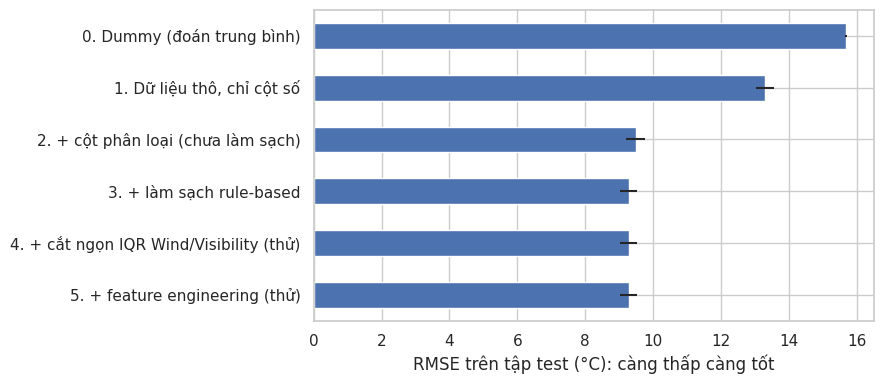

In [21]:
# Chạy lại 6 giai đoạn với 3 cách chia khác (mỗi cách chia là một cột)
runs = pd.concat([stage_main] + [run_stages(s) for s in [0, 1, 2]], axis=1)
robust = pd.DataFrame({'RMSE trung bình': runs.mean(axis=1),     # trung bình qua 4 cách chia
                       'Độ lệch chuẩn': runs.std(axis=1)})       # mức dao động giữa các cách chia
display(robust.round(3))

robust['RMSE trung bình'].plot(kind='barh', xerr=robust['Độ lệch chuẩn'], figsize=(9, 4))  # vạch lỗi = độ lệch chuẩn
plt.gca().invert_yaxis()                                         # giai đoạn 0 nằm trên cùng
plt.xlabel('RMSE trên tập test (°C): càng thấp càng tốt')
plt.tight_layout()
plt.show()

**Kết luận**

Kết quả cuối cùng (tập test): Linear Regression dùng đặc trưng gốc cho **RMSE ≈ 9,0°C, MAE ≈ 6,7°C, R² ≈ 0,67** (khoảng dao động 95% của RMSE ≈ 8,5 đến 9,4). Mô hình chỉ đoán trung bình (Dummy) có RMSE ≈ 15,7°C, nên sai số giảm khoảng 43%.

Mỗi bước đóng góp bao nhiêu:

| Bước | Tác động lên RMSE | Nhận xét |
|---|---|---|
| Đưa cột phân loại vào mô hình | Giảm lớn nhất: 13,30 → 9,48 (giảm 3,8°C) | Nhiệt độ phụ thuộc chủ yếu vào loại thời tiết, mùa và địa điểm. |
| Làm sạch rule-based | Giảm khoảng 0,2°C (9,48 → 9,28) | Cải thiện theo cùng chiều ở cả 4 cách chia (từ 0,15 đến 0,24).|
| Cắt ngọn IQR cho Wind/Visibility | Gần như không đổi (≤ 0,01) | Đây là giá trị có thật chứ không phải lỗi, nên không dùng |
| Feature engineering | Giảm khoảng 0,2°C (9,28 → 9,07) | Cải thiện theo cùng chiều ở cả 4 cách chia (từ 0,17 đến 0,25). |

**Diễn giải mô hình:** hệ số của Linear Regression cho thấy `Weather Type` có ảnh hưởng áp đảo: Sunny +10,3; Rainy +4,5; Cloudy +4,2; Snowy -18,9 (chênh lệch giữa Sunny và Snowy khoảng 29°C; hệ số của các nhóm one-hot chỉ có ý nghĩa khi so sánh với nhau trong cùng một cột).
